# Trial run — does Compass itself run correctly in *my* environment?

**Why this notebook exists.** Notebooks 1 and 2 never run Compass: they study the authors' precomputed output and re-solve a few linear programs with SciPy. Before your group invests CPU-days in real runs, you want to know three things: *(1) is the installation healthy, (2) does the Gurobi licence allow the real model size, and (3) do the numbers Compass produces here agree with the authors' published output?* This notebook answers them with a **short trial run (about 3–6 minutes)** and ends with a PASS / WARN / FAIL scoreboard.

**What it does *not* do:** it does not recompute all 10,211 reactions (that is ≈ 30 CPU-minutes *per cell*, **[Repo, docs]**). It uses the repo's hidden `--test-mode`, which evaluates only the **first 100 reactions and 50 metabolites** per cell **[Repo, compass/compass/algorithm.py]**, and it runs only a few cells. Every cell runs on the **full** Recon2 model, so a pass here means the real thing works.

### The ladder (each level assumes the previous one passed)
| Level | Test | Needs Gurobi? | Typical time |
|---|---|---|---|
| 1 | Python packages, `compass` import location, command-line script | no | seconds |
| 2 | Recon2 loads through the repo's code; cached `v_opt` matches the model | no | seconds |
| 3 | Gurobi: is there a licence, and is it **full** or **size-limited**? | yes | seconds |
| 4 | **Stage 1** through the real command line, paper settings, all 290 cells | licence *file* only | ≈ 0.5–2 min |
| 5 | **Stage 2** (the linear programs) for the first few cells, test mode | **full licence** | ≈ 1–3 min |
| 6 | Output is well-formed, and **agrees with the authors' `reactions.tsv`** | – | seconds |
| 7 | Independent check: re-solve some of the same LPs with SciPy/HiGHS | – | ≈ 20 s |

### How every statement is sourced
**[Paper]** = the uploaded paper · **[Repo]** = a file in the Compass repository (named) · **[Inference]** = my own reading, verify before relying on it.

### Why "agrees with the authors" is a fair test
A Compass score is the optimum of a linear program (LP). An LP optimum is a **unique number**, no matter which solver finds it — the authors used CPLEX, the current repo uses Gurobi, and Notebook 2 matched the authors' file with SciPy's HiGHS to ≈ 10⁻¹⁵ relative difference. So a correct installation must reproduce the authors' numbers up to the solver's tolerance (≈ 10⁻⁶ relative or better). A mismatch would mean a real problem (wrong settings, wrong model files, a numerical failure), not noise.

## 0 · Setup
### 0.1 Imports, environment check, and locating the Compass clone
**Run the two cells below first — every time the kernel restarts.** In VS Code pick your `che411` environment as the kernel (top right). **The only line you may need to edit is `REPO_PATH`** in the second cell.

In [13]:
import os, sys, re, json, time, shutil, tempfile, platform, subprocess, warnings
from pathlib import Path

try:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from scipy import sparse
    from scipy.optimize import linprog
except ModuleNotFoundError as e:
    _pip = {"sklearn": "scikit-learn"}.get(e.name.split(".")[0], e.name.split(".")[0])
    raise ModuleNotFoundError(
        f"The package '{e.name}' is not installed in the Python that runs this notebook:\n  {sys.executable}\n"
        f"Fix: copy this line into a terminal, then restart the kernel and run this cell again:\n"
        f"  \"{sys.executable}\" -m pip install {_pip}\n"
        "(If that path is not your che411 environment, pick che411 as the kernel instead.)") from None

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30, "display.width", 160, "display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# ---- environment check: lowest versions this notebook was written against (see requirements.txt) ----
from importlib.metadata import version, PackageNotFoundError
MIN_VERSIONS = {"numpy": "1.21", "pandas": "1.4", "scipy": "1.9", "matplotlib": "3.5"}
def _major_minor(v):
    return tuple(int(x) for x in re.findall(r"\d+", v)[:2])
print(f"Python {platform.python_version()}   |   this kernel runs: {sys.executable}")
too_old = []
for pkg, lowest in MIN_VERSIONS.items():
    try:
        have = version(pkg)
    except PackageNotFoundError:
        have = None
    ok = have is not None and _major_minor(have) >= _major_minor(lowest)
    print(f"  {'OK ' if ok else 'OLD'}  {pkg:<13} {have or 'unknown':<10} (needs >= {lowest})")
    if not ok:
        too_old.append(pkg)
if sys.version_info < (3, 10):
    print("! Python 3.10+ is recommended (the Compass repo itself requires it).")
if too_old:
    print("\n! Upgrade with:   python -m pip install -U " + " ".join(too_old) + "   then restart the kernel and re-run.")

Python 3.10.21   |   this kernel runs: /opt/anaconda3/envs/che411/bin/python
  OK   numpy         2.2.6      (needs >= 1.21)
  OK   pandas        2.3.3      (needs >= 1.4)
  OK   scipy         1.15.3     (needs >= 1.9)
  OK   matplotlib    3.10.9     (needs >= 3.5)


In [14]:
# =========================================================================================================
#  >>>  THE ONLY LINE YOU MAY NEED TO EDIT  <<<
#  The folder created by `git clone https://github.com/wagnerlab-berkeley/Compass.git`
#  (the one that contains README.md, compass/ and docs/).   macOS ignores letter case: ".../compass" also works.
REPO_PATH  = "/Users/willnath/Compass"
AUTO_CLONE = False          # True = if nothing is found, clone the repo into ./Compass (about 400 MB)
# =========================================================================================================

REPO_URL = "https://github.com/wagnerlab-berkeley/Compass.git"
MARKER   = "docs/notebooks/extdata/Th17/reactions.tsv"        # a file that exists only in the repo's top folder

def _is_repo(p):
    try:
        return (Path(p).expanduser() / MARKER).exists()
    except OSError:
        return False

def find_repo():
    """Return (repo_folder, how_it_was_found). Order: REPO_PATH, $COMPASS_REPO, this folder + parents, usual places."""
    cands = [("REPO_PATH", REPO_PATH), ("$COMPASS_REPO", os.environ.get("COMPASS_REPO"))]
    for up in [Path.cwd(), *Path.cwd().parents]:
        cands += [("the notebook's folder / a parent", up), ("a 'Compass' sub-folder", up / "Compass")]
    for sub in ["Compass", "compass", "Documents/Compass", "Documents/GitHub/Compass", "Desktop/Compass",
                "Downloads/Compass", "projects/Compass", "code/Compass", "GitHub/Compass"]:
        cands.append(("a usual place under your home folder", Path.home() / sub))
    for how, c in cands:
        if c and _is_repo(c):
            return Path(c).expanduser().resolve(), how
    return None, None

REPO, how_found = find_repo()
if REPO is None and AUTO_CLONE:
    print("Compass repo not found locally - cloning (shallow) into ./Compass ...")
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "Compass"], check=True)
    REPO, how_found = find_repo()
if REPO is None:
    raise FileNotFoundError(
        f"Could not find the Compass repository (looked for the file {MARKER}).\n"
        f"  REPO_PATH is currently '{REPO_PATH}'.\n"
        "  Fix 1: set REPO_PATH (above) to your clone. In a terminal:  cd <your clone>  and run  pwd  to print the path.\n"
        f"  Fix 2: not cloned yet?  git clone {REPO_URL}   (or set AUTO_CLONE = True)")
if how_found != "REPO_PATH":
    print(f"! REPO_PATH ('{REPO_PATH}') does not contain the repo; using the clone found via: {how_found}.\n")

DATA = REPO / "docs/notebooks/extdata"                         # Th17/ and RECON2/ live here
RES       = REPO / "compass/Resources"
# ---- every file this notebook reads (path relative to the repo folder -> what it is) ----
REQUIRED = {
    'docs/notebooks/extdata/Th17/linear_gene_expression_matrix.tsv': "the paper's input: gene x 290-cell TPM matrix",
    'docs/notebooks/extdata/Th17/reactions.tsv': "the AUTHORS' Compass output = the reference we compare with",
    'compass/main.py': 'Compass command-line program',
    'compass/Resources/COMPASS/RECON2_mat/default-media/preprocess.json': 'cached maximal fluxes v_opt (stage 0)',
    'compass/Resources/Metabolic Models/RECON2_mat/model/model.S.json': 'Recon2 model files',
}
OPTIONAL = {}

ALL_FILES = {**REQUIRED, **OPTIONAL}
missing, w = [], max(len(k) for k in ALL_FILES)
for rel, what in ALL_FILES.items():
    p = REPO / rel
    ok = p.is_file() and p.stat().st_size > 0
    tag = "OK " if ok else ("-- " if rel in OPTIONAL else "!! ")
    size = f"{p.stat().st_size / 1e6:8.2f} MB" if ok else "     MISSING"
    print(f"{tag}{rel:<{w}} {size}   {what}")
    if not ok and rel in REQUIRED:
        missing.append(rel)
if missing:
    raise FileNotFoundError(
        f"{len(missing)} required file(s) are missing inside {REPO}:\n  " + "\n  ".join(missing) +
        "\nLikely cause: the clone is incomplete or REPO_PATH points to the wrong folder."
        f"\n  Check:  git -C \"{REPO}\" status     Repair:  git -C \"{REPO}\" checkout -- .   (or re-clone)")

print(f"\nRepo    : {REPO}   (found via {how_found})\nData    : {DATA}")

OK docs/notebooks/extdata/Th17/linear_gene_expression_matrix.tsv         30.52 MB   the paper's input: gene x 290-cell TPM matrix
OK docs/notebooks/extdata/Th17/reactions.tsv                             38.74 MB   the AUTHORS' Compass output = the reference we compare with
OK compass/main.py                                                        0.09 MB   Compass command-line program
OK compass/Resources/COMPASS/RECON2_mat/default-media/preprocess.json     0.50 MB   cached maximal fluxes v_opt (stage 0)
OK compass/Resources/Metabolic Models/RECON2_mat/model/model.S.json       0.87 MB   Recon2 model files

Repo    : /Users/willnath/Compass   (found via REPO_PATH)
Data    : /Users/willnath/Compass/docs/notebooks/extdata


### 0.2 Knobs and the scoreboard
Defaults give a 3–6 minute trial. Nothing here changes the repository; everything is written to the folder `compass_trial/` next to this notebook (delete it any time).

In [15]:
N_CELLS      = 3        # cells sent through stage 2 = the FIRST N cells of the Th17 matrix (all Th17p - the group is irrelevant for a numerical check)
RUN_STAGE2   = "auto"   # "auto": only if a FULL Gurobi licence is detected | True: always try | False: never
TIMEOUT_MIN  = 20       # kill a Compass run that takes longer than this many minutes
N_REPLICATE  = 10       # reactions per cell re-solved with SciPy/HiGHS in level 7 (0 = skip level 7)
TOL_PASS     = 1e-4     # PASS if every value agrees within this RELATIVE difference (Gurobi's default tolerances give about 1e-6 or better)
TOL_WARN     = 1e-2     # WARN between TOL_PASS and this; FAIL above
FRESH_RUN    = True     # True: delete the previous trial folder first (needed for a clean test)
GUROBI_LICENSE = "installed"  # "installed": Compass uses the Gurobi you already have installed and licensed (gurobipy finds your licence by itself). The notebook only puts an EMPTY placeholder gurobi.lic into the Compass folder because the command line insists the file exists; no secret is copied.  |  "copy": copy the licence file Gurobi uses (GRB_LICENSE_FILE, ~/gurobi.lic, ...) into the Compass folder with `compass --set-license`  |  a path: copy that file instead

WORK = Path.cwd() / "compass_trial"
RUN  = WORK / "run"                     # Compass --output-dir  (its temp folder is run/_tmp)
N_PROC_STAGE1 = max(1, min(os.cpu_count() or 1, 8))
N_PROC_STAGE2 = max(1, min(N_CELLS, os.cpu_count() or 1))

CHECKS = []                              # the scoreboard rows
STATE  = {}                              # facts carried from one level to the next
ICON = {"PASS": "[PASS]", "WARN": "[WARN]", "FAIL": "[FAIL]", "SKIP": "[SKIP]"}
def record(level, name, status, detail=""):
    CHECKS.append({"level": level, "check": name, "status": status, "detail": detail})
    print(f"{ICON[status]}  L{level}  {name}" + (f"  -  {detail}" if detail else ""))

## Level 1 · Is the installation healthy?
Compass imports a long list of packages **at start-up** (`pyproject.toml`: numpy, pandas, tqdm, python-libsbml, six, scikit-learn, scipy, python-igraph, leidenalg, anndata, gurobipy, session-info **[Repo]**). If one is missing or its compiled library does not load, the program stops before doing anything. We test each one, then ask a **fresh Python process started in a neutral folder** where `compass` is imported from — that is exactly what the command line will do, and it tells us whether you installed your clone (`pip install -e`) or a separate copy.

In [16]:
import importlib, tempfile
from importlib.metadata import version, PackageNotFoundError

NEEDED = [("numpy", "numpy"), ("pandas", "pandas"), ("scipy", "scipy"), ("sklearn", "scikit-learn"), ("tqdm", "tqdm"),
          ("six", "six"), ("libsbml", "python-libsbml"), ("igraph", "python-igraph"), ("leidenalg", "leidenalg"),
          ("anndata", "anndata"), ("gurobipy", "gurobipy"), ("session_info", "session-info")]

def probe_compass(extra_env=None):
    """Import compass in a NEW Python process started in a neutral folder; return (info, error_line)."""
    probe = ("import json, compass, compass.globals as g\n"
             "print(json.dumps({'file': compass.__file__, 'license_dir': g.LICENSE_DIR}))")
    r = subprocess.run([sys.executable, "-c", probe], cwd=tempfile.gettempdir(), env={**os.environ, **(extra_env or {})},
                       capture_output=True, text=True)
    if r.returncode == 0:
        return json.loads(r.stdout.strip().splitlines()[-1]), None
    return None, (r.stderr.strip().splitlines() or ["unknown error"])[-1]

def level1():
    # (a) packages -------------------------------------------------------------------------------------------
    rows, bad = [], []
    for mod, pipname in NEEDED:
        try:
            importlib.import_module(mod)
            try: v = version(pipname)
            except PackageNotFoundError: v = "?"
            rows.append((pipname, v, "ok"))
        except Exception as e:                          # missing package OR a compiled library that fails to load
            rows.append((pipname, "-", f"{type(e).__name__}: {str(e)[:70]}")); bad.append(pipname)
    print(pd.DataFrame(rows, columns=["package", "version", "import"]).to_string(index=False), "\n")
    if bad:
        record(1, "packages Compass needs at start-up", "FAIL",
               f"missing or broken: {', '.join(bad)}.  Fix:  \"{sys.executable}\" -m pip install {' '.join(bad)}")
        return
    record(1, "packages Compass needs at start-up", "PASS", f"all {len(NEEDED)} import")

    # (b) where does `compass` come from? ---------------------------------------------------------------------
    env = dict(os.environ)
    info, err = probe_compass()
    if info is None:
        info2, err2 = probe_compass({"PYTHONPATH": str(REPO)})
        if info2 is None:
            record(1, "import compass", "FAIL", f"{err2}   (repo: {REPO})")
            return
        env["PYTHONPATH"] = str(REPO) + (os.pathsep + os.environ["PYTHONPATH"] if os.environ.get("PYTHONPATH") else "")
        info = info2
        record(1, "import compass", "WARN",
               f"not installed in this Python; using your clone through PYTHONPATH (fine for this test). For daily use run:  "
               f"\"{sys.executable}\" -m pip install -e \"{REPO}\"")
    else:
        where = Path(info["file"]).resolve()
        if REPO in where.parents:
            record(1, "import compass", "PASS", f"installed from your clone: {where.parent}")
        else:
            record(1, "import compass", "WARN",
                   f"a separate copy in {where.parent} is used, NOT your clone - edits to the clone will not affect it")
    STATE["env"] = env
    STATE["license_dir"] = Path(info["license_dir"])
    STATE["lic_file"] = STATE["license_dir"] / "gurobi.lic"

    # (c) how do we start the command line? --------------------------------------------------------------------
    script = Path(sys.executable).parent / ("compass.exe" if os.name == "nt" else "compass")
    if script.exists():
        STATE["cmd"] = [str(script)]
        record(1, "`compass` command", "PASS", f"console script next to this Python: {script}")
    else:
        STATE["cmd"] = [sys.executable, "-c", "from compass.main import entry; entry()"]
        record(1, "`compass` command", "WARN", "no console script next to this Python; starting it with `python -c` instead (equivalent)")
    STATE["level1_ok"] = True

level1()
if STATE.get("env") is not None:
    print("\nCompass folder (where it looks for gurobi.lic):", STATE["license_dir"])

       package version import
         numpy   2.2.6     ok
        pandas   2.3.3     ok
         scipy  1.15.3     ok
  scikit-learn   1.7.2     ok
          tqdm  4.70.1     ok
           six  1.17.0     ok
python-libsbml  5.21.1     ok
 python-igraph   1.0.0     ok
     leidenalg  0.12.0     ok
       anndata  0.11.4     ok
      gurobipy  13.0.3     ok
  session-info   1.0.1     ok 

[PASS]  L1  packages Compass needs at start-up  -  all 12 import
[PASS]  L1  import compass  -  installed from your clone: /Users/willnath/Compass/compass
[PASS]  L1  `compass` command  -  console script next to this Python: /opt/anaconda3/envs/che411/bin/compass

Compass folder (where it looks for gurobi.lic): /Users/willnath/Compass/compass


## Level 2 · Does the model load, and is the cache consistent?
Compass builds the metabolic network from JSON files in `compass/Resources/Metabolic Models/RECON2_mat/` (reversible reactions are split into `_pos` / `_neg`, exchange uptake is capped at 1.0, the medium is applied) **[Repo, models/__init__.py]**. It also needs `v_opt` — the maximal flux of every reaction, Algorithm 1 in the paper — which the authors ship precomputed in `preprocess.json` so that nobody has to solve 10,211 LPs first **[Repo, cache.py]**. We load both through the repo's own code and check that they belong together and match the authors' output file.

In [17]:
def level2():
    if not STATE.get("level1_ok"):
        return record(2, "model + cache", "SKIP", "level 1 did not pass")
    if STATE["env"].get("PYTHONPATH"):
        sys.path.insert(0, STATE["env"]["PYTHONPATH"].split(os.pathsep)[0])
    try:
        from compass import models as cmodels, globals as cglobals
        from compass.compass import cache as ccache
        cm = cmodels.init_model("RECON2_mat", species="mus_musculus", exchange_limit=cglobals.EXCHANGE_LIMIT,
                                media="default-media", isoform_summing="legacy")
    except Exception as e:
        return record(2, "model loads through the repo's code", "FAIL", f"{type(e).__name__}: {str(e)[:200]}")
    STATE.update(cm=cm, ccache=ccache, BETA=cglobals.BETA)
    ref = pd.read_csv(DATA / "Th17/reactions.tsv", sep="\t", index_col=0)           # the authors' output
    STATE["ref"] = ref
    n_rxn, n_met = len(cm.reactions), len(cm.species)
    print(f"model: {n_rxn:,} unidirectional reactions, {n_met:,} metabolites, species mus_musculus, medium default-media")
    same = set(cm.reactions) == set(ref.index)
    record(2, "model loads; reaction set equals the authors' output", "PASS" if same else "FAIL",
           f"{n_rxn:,} reactions" + ("" if same else f" vs {len(ref):,} in the authors' reactions.tsv"))
    vopt = ccache.load(cm)
    STATE["vopt"] = vopt
    covered = set(vopt) >= set(cm.reactions)
    zero = float(np.mean([vopt[r] == 0 for r in cm.reactions if r in vopt]))
    print(f"cached v_opt: {len(vopt):,} entries; {zero:.0%} are 0 (reactions that can never carry flux; paper: 33% blocked)")
    record(2, "cached v_opt covers every reaction", "PASS" if covered else "FAIL", f"{len(vopt):,} entries")
    STATE["level2_ok"] = same and covered

level2()

model: 10,211 unidirectional reactions, 5,063 metabolites, species mus_musculus, medium default-media
[PASS]  L2  model loads; reaction set equals the authors' output  -  10,211 reactions
cached v_opt: 18,616 entries; 33% are 0 (reactions that can never carry flux; paper: 33% blocked)
[PASS]  L2  cached v_opt covers every reaction  -  18,616 entries


## Level 3 · Gurobi: is there a licence, and is it big enough?
Compass solves its LPs with **Gurobi** (the original CPLEX was replaced **[Repo, CHANGELOG]**). Three separate things can go wrong, and the error messages you would otherwise meet are confusing:

1. **A file the command line insists on.** The `compass` command refuses to start unless a file called `gurobi.lic` exists **inside the Compass package folder** (`main.py: entry()`), even when Gurobi finds your licence elsewhere. With `GUROBI_LICENSE = "installed"` (the default) the cell below creates an **empty placeholder** there (comment lines only, no credentials), so Compass falls back to **the Gurobi you installed and licensed** (`gp.Env()`); nothing secret is copied into your git clone. `"copy"` or a path copies a real licence file instead.
2. **A size-limited licence.** The licence that comes with `pip install gurobipy` allows only **2,000 variables / 2,000 constraints**. The Recon2 LP has **10,211 variables and 5,063 constraints** (Notebook 2), so Compass fails with *"Model too large for size-limited license"*. An **academic licence** (free, via a Gurobi account) removes the limit.
3. **A licence Compass cannot see.** Compass reads only WLS credentials (`WLSACCESSID`, `WLSSECRET`, `LICENSEID`) from that file; with anything else (an empty placeholder, a named-user file) it calls `gp.Env()`, which searches Gurobi's usual places (`GRB_LICENSE_FILE`, `~/gurobi.lic`, `/Library/gurobi`, …) **[Repo, utils.py + opt/gurobi.py]**. The notebook runs Compass in the same environment as itself, so if Gurobi works here, it works there.

The cell below replays exactly this logic, then tests the licence by **solving a tiny LP and an LP with 2,100 variables** (just over the limit). Nothing here prints your secret.

In [18]:
def find_gurobi_license_file():
    """The licence FILE Gurobi itself uses on this computer, if there is one (the places Gurobi searches by default)."""
    for c in [os.environ.get("GRB_LICENSE_FILE"), Path.home() / "gurobi.lic", "/Library/gurobi/gurobi.lic",
              "/opt/gurobi/gurobi.lic", Path.home() / "gurobi" / "gurobi.lic"]:
        if c and Path(c).expanduser().is_file():
            return Path(c).expanduser()
    return None

def parse_license_like_compass(path):
    """Read a licence file exactly the way Compass does (utils.parse_gurobi_license_file): every line containing '=' is split
    into KEY and VALUE; a line with TWO or more '=' makes `key, val = line.split('=')` crash. Uses Compass' own function when
    it can be imported, otherwise an identical copy of its logic."""
    try:
        from compass import utils as cutils
        return cutils.parse_gurobi_license_file(str(path))
    except ImportError:
        creds = {}
        with open(path, "r") as fh:
            for line in fh:
                line = line.strip()
                if "=" in line:
                    key, val = line.split("=")
                    try: val = int(val)
                    except ValueError: pass
                    creds[key] = val
        return creds

PLACEHOLDER_TEXT = (
    "# Placeholder written by 04_Compass_trial_run_validity_check.ipynb\n"
    "# Compass only checks that this file exists. It holds no credentials, so Compass uses the Gurobi licence that gurobipy finds by itself.\n")

def level3():
    if not STATE.get("level1_ok"):
        return record(3, "Gurobi licence", "SKIP", "level 1 did not pass")
    lic = STATE["lic_file"]
    found = find_gurobi_license_file()

    # (a) the file the command line insists on --------------------------------------------------------------------
    # main.py: entry() quits unless <Compass folder>/gurobi.lic exists. algorithm.py then reads WLS keys from it if all three are
    # present and otherwise calls gp.Env() = Gurobi's own licence lookup (the Gurobi you installed).
    mode = GUROBI_LICENSE
    if not lic.exists():
        if mode == "installed":
            try:
                lic.write_text(PLACEHOLDER_TEXT)
                print(f"The Compass folder had no gurobi.lic. Wrote an EMPTY placeholder (no credentials) at {lic}\n"
                      "   -> Compass will use the Gurobi you installed and licensed (gp.Env() finds your licence by itself).")
            except OSError as e:
                print(f"Could not write the placeholder: {type(e).__name__}: {e}")
        elif mode:  # "copy" or a path: copy a real licence file with Compass' own documented command
            src = found if mode == "copy" else Path(mode).expanduser()
            if src is None:
                print("The Compass folder has no gurobi.lic and no licence file was found in the usual places "
                      "(GRB_LICENSE_FILE, ~/gurobi.lic, /Library/gurobi, /opt/gurobi) - nothing to copy.")
            else:
                print(f"The Compass folder has no gurobi.lic. Copying  {src}  into it with Compass' own documented command (compass --set-license) ...")
                r = subprocess.run(STATE["cmd"] + ["--set-license", str(src)], cwd=tempfile.gettempdir(), env=STATE["env"],
                                   capture_output=True, text=True, stdin=subprocess.DEVNULL)
                print("   ->", (r.stdout or r.stderr).strip()[:200])

    creds = {}
    if lic.exists():
        try:
            creds = parse_license_like_compass(lic)
            if all(k in creds for k in ("WLSACCESSID", "WLSSECRET", "LICENSEID")):
                kind = "contains WLS credentials: Compass uses THESE"
            elif creds:
                kind = "keys but no WLS credentials: Compass ignores them and uses Gurobi's own licence lookup"
            else:
                kind = "no credentials: Compass uses the Gurobi you installed (Gurobi's own licence lookup)"
            record(3, "gurobi.lic in the Compass folder (needed by the command line)", "PASS", f"{lic}  [{kind}]")
        except Exception as e:
            creds = {}
            record(3, "gurobi.lic in the Compass folder can be read by Compass", "FAIL",
                   f"{type(e).__name__}: {str(e)[:120]}  (Compass reads this file line by line as KEY=VALUE; stage 2 would crash on it). "
                   "Fix: delete that file and set GUROBI_LICENSE = \"installed\" in cell 0.2")
        if creds and (REPO / ".git").exists() and REPO in lic.resolve().parents:
            print("   note: this file lives INSIDE your git clone, holds licence keys and the repo's .gitignore does not exclude it - never `git add` it.")
    else:
        record(3, "gurobi.lic in the Compass folder (needed by the command line)", "FAIL",
               f"not found at {lic}.  Fix: set GUROBI_LICENSE = \"installed\" in cell 0.2 (creates an empty placeholder), "
               "or once in a terminal:  compass --set-license ~/gurobi.lic")
    STATE["lic_ok"] = lic.exists()

    # (b) what does Gurobi itself allow? (same environment logic as opt/gurobi.py) ----------------------------------------
    try:
        import gurobipy as gp
        from gurobipy import GRB
        env = gp.Env(empty=True); env.setParam("OutputFlag", 0)
        if all(k in creds for k in ("WLSACCESSID", "WLSSECRET", "LICENSEID")):
            for k in ("WLSACCESSID", "WLSSECRET", "LICENSEID"): env.setParam(k, creds[k])
        env.start()
        m = gp.Model(env=env); x = m.addVars(2, lb=0, ub=10); m.addConstr(x[0] + x[1] >= 1); m.setObjective(x[0] + x[1], GRB.MINIMIZE); m.optimize()
        assert m.Status == GRB.OPTIMAL and abs(m.ObjVal - 1.0) < 1e-9
        v = gp.gurobi.version()
        record(3, "Gurobi starts and solves a tiny LP", "PASS", f"gurobipy {v[0]}.{v[1]}.{v[2]}")
    except Exception as e:
        STATE["gurobi"] = "NONE"
        return record(3, "Gurobi starts and solves a tiny LP", "FAIL", f"{type(e).__name__}: {str(e)[:160]}")
    try:
        m = gp.Model(env=env); y = m.addVars(2100, lb=0, ub=1); m.addConstr(y.sum() >= 1); m.setObjective(y.sum(), GRB.MINIMIZE); m.optimize()
        STATE["gurobi"] = "FULL"
        record(3, "licence size", "PASS", "FULL - solved a 2,100-variable LP, so Recon2 (10,211 variables) is allowed")
    except gp.GurobiError as e:
        if "too large" in str(e).lower():
            STATE["gurobi"] = "RESTRICTED"
            record(3, "licence size", "FAIL",
                   "SIZE-LIMITED licence (max 2,000 variables). Compass on Recon2 needs a full licence: get the free academic (WLS) licence "
                   "via gurobi.com/unrestricted and save the file as ~/gurobi.lic (the installed Gurobi finds it by itself), then re-run from Level 3")
        else:
            STATE["gurobi"] = "NONE"
            record(3, "licence size", "FAIL", f"{str(e)[:160]}")

level3()

[PASS]  L3  gurobi.lic in the Compass folder (needed by the command line)  -  /Users/willnath/Compass/compass/gurobi.lic  [no credentials: Compass uses the Gurobi you installed (Gurobi's own licence lookup)]
[PASS]  L3  Gurobi starts and solves a tiny LP  -  gurobipy 13.0.3
[PASS]  L3  licence size  -  FULL - solved a 2,100-variable LP, so Recon2 (10,211 variables) is allowed


## Level 4 · Stage 1 through the real command line (paper settings, all 290 cells)
**What stage 1 does** (Algorithm 2, first half **[Paper]**): for each cell, evaluate every reaction's gene rule (OR = sum, AND = mean), take log₂(x+1), smooth over the 10 nearest-neighbour cells (λ = 0.25), and turn the result into a **penalty per reaction**: `(1−λ)/(1+R) + λ/(1+R_neighbours)`. Highly expressed ⇒ penalty near 0; no expression support, or no gene rule at all ⇒ penalty 1. No linear program is solved yet, so this level needs no Gurobi licence — only the licence *file* that the command line checks for.

**The command is the paper's** (see `README_SETUP.md` §2.6 **[Repo, docs/notebooks/postprocessing.ipynb]**): `--lambda 0.25 --and-function mean --penalty-diffusion knn --num-neighbors 10 --isoform-summing legacy`. They differ from the command-line *defaults* (λ = 0, k = 30, isoform repeats removed) — running Compass without them would **not** reproduce the paper. Smoothing uses all 290 cells, which is why stage 1 must see the full matrix even though we later run only a few cells through stage 2. `--only-penalties` stops after stage 1 **[Repo, settings.rst]**.

**What we check:** the penalty table has one row per reaction and one column per cell; every penalty lies in (0, 1]; and reactions *without* a gene rule have penalty exactly 1 in every cell (nothing in the transcriptome can inform them — Notebook 2, part C).

In [19]:
SIGNATURES = [
    ("a gurobi license is required", "Compass wants a gurobi.lic file inside its own folder. Re-run Level 3 with GUROBI_LICENSE = \"installed\" (creates an empty placeholder) or run once:  compass --set-license ~/gurobi.lic"),
    ("too large for size-limited license", "Size-limited Gurobi licence (max 2,000 variables). Recon2 needs the full academic licence."),
    ("no gurobi license found", "Gurobi cannot find a licence by itself. Put your gurobi.lic in your home folder (~/gurobi.lic) or set GRB_LICENSE_FILE in the environment that starts the notebook; or use GUROBI_LICENSE = \"copy\" (WLS keys are then read from the Compass folder's gurobi.lic)."),
    ("expired", "A licence has expired - renew it in the Gurobi user portal (academic licences last one year)."),
    ("modulenotfounderror", "A Python package is missing in the environment that runs Compass (the module name is in the error text)."),
    ("memoryerror", "Out of memory - lower N_CELLS / --num-processes."),
]
def diagnose(text):
    t = text.lower()
    tips = [tip for key, tip in SIGNATURES if key in t]
    if not tips and "licen" in t:
        tips = ["A Gurobi licence problem (see level 3). If the message mentions a session or usage limit, set N_CELLS = 1 so only one process uses the licence at a time."]
    return tips

def run_compass(args, label, watch=None):
    """Run the Compass command line as a separate process; poll it so the notebook shows life signs."""
    out_f, err_f = WORK / f"{label}.out.txt", WORK / f"{label}.err.txt"
    t0, last = time.time(), 0
    with open(out_f, "w") as fo, open(err_f, "w") as fe:
        p = subprocess.Popen(STATE["cmd"] + args, cwd=WORK, env={**STATE["env"], "PYTHONUNBUFFERED": "1"},
                             stdout=fo, stderr=fe, stdin=subprocess.DEVNULL)
        while p.poll() is None:
            time.sleep(1)
            el = time.time() - t0
            if el - last >= 15:
                print(f"   ... {el:4.0f} s elapsed" + (f"   {watch()}" if watch else "")); last = el
            if el > TIMEOUT_MIN * 60:
                p.kill(); p.wait()
                return {"code": None, "secs": el, "timeout": True}
    return {"code": p.returncode, "secs": time.time() - t0, "timeout": False}

def failure_text(label):
    txt = ""
    for f in (WORK / f"{label}.out.txt", WORK / f"{label}.err.txt", *RUN.glob("_tmp/sample*/err.log")):
        if f.exists(): txt += f.read_text(errors="replace") + "\n"
    return txt

def explain_failure(level, name, res, label):
    txt = failure_text(label)
    tips = diagnose(txt)
    why = "timed out after %d min" % TIMEOUT_MIN if res["timeout"] else f"exit code {res['code']}"
    tail = [l for l in txt.replace("\r", "\n").splitlines() if l.strip() and "it/s" not in l and "s/it" not in l][-6:]
    record(level, name, "FAIL", why + ("  |  " + " ".join(tips) if tips else ""))
    print("   last lines of the error output:\n     " + "\n     ".join(l[:170] for l in tail))
    print(f"   full logs: {WORK}")

def level4():
    if not STATE.get("level2_ok"):
        return record(4, "stage 1 (penalties)", "SKIP", "level 2 did not pass")
    if not STATE.get("lic_ok"):
        return record(4, "stage 1 (penalties)", "SKIP", "the command line needs gurobi.lic in the Compass folder - see level 3")
    if FRESH_RUN:
        shutil.rmtree(WORK, ignore_errors=True)
    RUN.mkdir(parents=True, exist_ok=True)
    data_file = WORK / "th17_expr.tsv"
    shutil.copyfile(DATA / "Th17/linear_gene_expression_matrix.tsv", data_file)
    STATE["data_file"] = data_file
    STATE["common_args"] = ["--data", str(data_file), "--model", "RECON2_mat", "--species", "mus_musculus", "--media", "default-media",
                            "--lambda", "0.25", "--and-function", "mean", "--penalty-diffusion", "knn", "--num-neighbors", "10",
                            "--isoform-summing", "legacy", "--output-dir", str(RUN), "--test-mode"]
    print(f"stage 1: 290 cells, {N_PROC_STAGE1} process(es) ... (about 0.5-2 min)")
    res = run_compass(STATE["common_args"] + ["--only-penalties", "--num-processes", str(N_PROC_STAGE1)], "stage1")
    pen_file = RUN / "_tmp" / "penalties.txt.gz"
    if res["timeout"] or res["code"] != 0 or not pen_file.exists():
        return explain_failure(4, "stage 1 runs", res, "stage1")
    record(4, "stage 1 runs", "PASS", f"finished in {res['secs']:.0f} s")
    pen = pd.read_csv(pen_file, sep="\t", index_col=0)
    STATE["pen1"] = pen
    all_cells = list(pd.read_csv(data_file, sep="\t", index_col=0, nrows=1).columns)
    ok_shape = pen.shape == (len(STATE["cm"].reactions), len(all_cells)) and list(pen.columns) == all_cells
    record(4, "penalty table has one row per reaction and one column per cell", "PASS" if ok_shape else "FAIL", f"{pen.shape[0]:,} x {pen.shape[1]}")
    lo, hi = float(pen.values.min()), float(pen.values.max())
    ok_rng = np.isfinite(pen.values).all() and lo > 0 and hi <= 1 + 1e-9
    record(4, "every penalty lies in (0, 1]", "PASS" if ok_rng else "FAIL", f"min {lo:.4f}, max {hi:.4f}")
    no_rule = [r for r in pen.index if len(STATE["cm"].reactions[r].list_genes()) == 0]          # reactions with no gene in the model
    ones = float((np.abs(pen.loc[no_rule].values - 1) < 1e-9).all(axis=1).mean()) if no_rule else np.nan
    record(4, "reactions without a gene rule have penalty exactly 1", "PASS" if ones == 1 else "WARN", f"{ones:.1%} of {len(no_rule):,} such reactions")
    STATE["stage1_ok"] = ok_shape and ok_rng

level4()

stage 1: 290 cells, 8 process(es) ... (about 0.5-2 min)
   ...   15 s elapsed
[PASS]  L4  stage 1 runs  -  finished in 21 s
[PASS]  L4  penalty table has one row per reaction and one column per cell  -  10,211 x 290
[PASS]  L4  every penalty lies in (0, 1]  -  min 0.0522, max 1.0000
[PASS]  L4  reactions without a gene rule have penalty exactly 1  -  100.0% of 4,074 such reactions


## Level 5 · Stage 2 — the linear programs (this is where Gurobi works)
**What stage 2 does** (Algorithm 2, second half **[Paper]**): for each reaction *r* and each cell, solve

`minimise Σ penalty_i · v_i   subject to   S·v = 0,  flux bounds,  reverse reaction blocked,  v_r ≥ 0.95 · v_r^opt`

The minimum is that reaction's Compass penalty in that cell. "0.95 · v_r^opt" (`BETA` in `compass/globals.py`) forces reaction *r* to run near its maximum, so the answer measures **how cheaply the whole network can support that reaction given this cell's expression**.

**How we run only a few cells although smoothing needs all 290.** Compass saves the stage-1 penalties in its temporary folder and *resumes* from there ("Resuming execution from previous run…", `main.py`; `README_SETUP.md` §2.6). We overwrite the data file with its **first `N_CELLS` columns** and start Compass again with the same settings: it finds the saved penalties, skips stage 1, and runs stage 2 for those cells only. Their penalties are the ones computed from all 290 cells — exactly what the authors used.

**Test mode** limits each cell to the first 100 reactions plus the exchange reactions of the first 50 metabolites. The cells run in parallel (`N_PROC_STAGE2` processes).

In [20]:
def level5():
    if not STATE.get("stage1_ok"):
        return record(5, "stage 2 (linear programs)", "SKIP", "stage 1 did not pass")
    if RUN_STAGE2 is False:
        return record(5, "stage 2 (linear programs)", "SKIP", "RUN_STAGE2 = False")
    if RUN_STAGE2 == "auto" and STATE.get("gurobi") != "FULL":
        return record(5, "stage 2 (linear programs)", "SKIP",
                      f"Gurobi licence status is {STATE.get('gurobi', 'unknown')}; stage 2 needs a FULL licence. Fix level 3 (or set RUN_STAGE2 = True to try anyway)")
    data_file = STATE["data_file"]
    full = pd.read_csv(data_file, sep="\t", index_col=0)
    cells = list(full.columns[:N_CELLS])
    full.iloc[:, :N_CELLS].to_csv(data_file, sep="\t")                      # same path, first N cells only (see text above)
    STATE["cells"] = cells
    watch = lambda: f"cells finished: {len(list(RUN.glob('_tmp/sample*/success_token')))}/{N_CELLS}"
    print(f"stage 2: {N_CELLS} cells on {N_PROC_STAGE2} process(es). Expect roughly 0.5-2 minutes per cell; the cells run in parallel.")
    res = run_compass(STATE["common_args"] + ["--num-processes", str(N_PROC_STAGE2)], "stage2", watch)
    if res["timeout"] or res["code"] != 0 or not (RUN / "reactions.tsv").exists():
        return explain_failure(5, "Compass finishes stage 2", res, "stage2")
    STATE["stage2_secs"] = res["secs"]
    record(5, "Compass finishes stage 2", "PASS", f"{N_CELLS} cells in {res['secs']:.0f} s")
    STATE["stage2_done"] = True

level5()

stage 2: 3 cells on 3 process(es). Expect roughly 0.5-2 minutes per cell; the cells run in parallel.
[PASS]  L5  Compass finishes stage 2  -  3 cells in 14 s


## Level 6 · Is the output right? (the decisive test)
Two questions:

1. **Is the file well-formed?** One column per cell, no missing values, no negative penalties (a penalty is a sum of non-negative terms: penalties ≥ 0 and fluxes ≥ 0).
2. **Does it agree with the authors?** For every reaction and cell that is in *both* our file and the authors' `reactions.tsv`, compute the **relative difference** `|a − b| / max(|a|, |b|)`. Two quantities are reported: the **zero / non-zero pattern** (a score is exactly 0 when the reaction cannot carry flux, `v_opt = 0` — this depends only on the model and cache) and the **size of the differences** among non-zero scores (this depends on the penalties *and* the LP solver).

**How to read the figure.** Left: each dot is one (reaction, cell) score; if our run reproduces the authors', all dots sit on the diagonal. Axes are logarithmic because scores span orders of magnitude. Right: histogram of the relative differences on a log scale — a peak far to the left (10⁻⁹ or smaller) means agreement to numerical precision; differences near 10⁻² would mean something is really different.

[PASS]  L6  output file is well-formed  -  106 reactions x 3 cells, no missing values, none negative
[PASS]  L6  agrees with the authors' reactions.tsv  -  222 non-zero scores compared (+96 exact zeros); max relative difference 1.8e-15, median 2.1e-16; zero/non-zero pattern differs in 0 entries


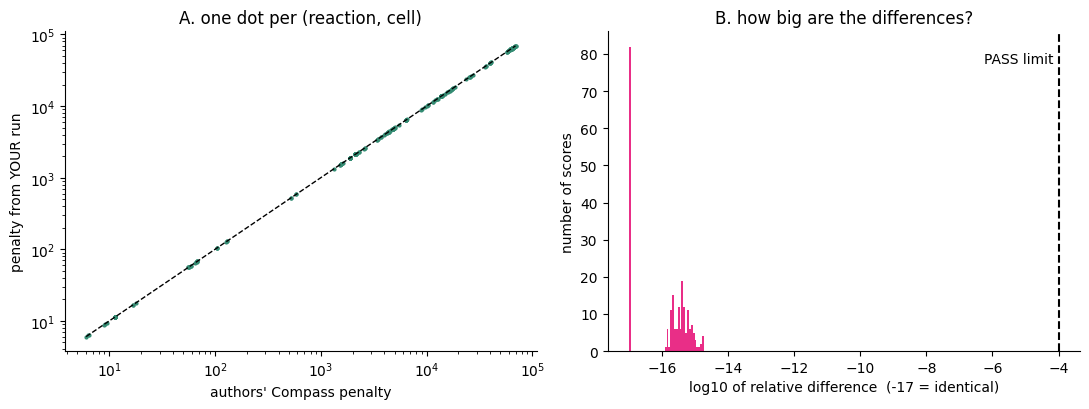

In [21]:
def level6():
    if not STATE.get("stage2_done"):
        return record(6, "output checks", "SKIP", "stage 2 did not run")
    ours = pd.read_csv(RUN / "reactions.tsv", sep="\t", index_col=0)
    cells = STATE["cells"]; ref = STATE["ref"]
    problems = []
    if list(ours.columns) != cells: problems.append("columns differ from the cells that were run")
    if ours.isna().any().any(): problems.append(f"{int(ours.isna().sum().sum())} missing values")
    if (ours.values < 0).any(): problems.append("negative penalties")
    record(6, "output file is well-formed", "FAIL" if problems else "PASS",
           "; ".join(problems) if problems else f"{ours.shape[0]:,} reactions x {ours.shape[1]} cells, no missing values, none negative")
    if problems: return
    STATE["ours"] = ours

    rows = ours.index.intersection(ref.index)
    a = ours.loc[rows, cells].to_numpy(float); b = ref.loc[rows, cells].to_numpy(float)
    zero_diff = int(((a == 0) != (b == 0)).sum())
    nz = (a != 0) & (b != 0)
    rel = np.abs(a[nz] - b[nz]) / np.maximum(np.abs(a[nz]), np.abs(b[nz]))
    worst, med = (float(rel.max()), float(np.median(rel))) if rel.size else (np.nan, np.nan)
    if rel.size == 0 or zero_diff > 0:
        status = "FAIL"
    else:
        status = "PASS" if worst <= TOL_PASS else ("WARN" if worst <= TOL_WARN else "FAIL")
    record(6, "agrees with the authors' reactions.tsv", status,
           f"{nz.sum():,} non-zero scores compared (+{int((~nz).sum()):,} exact zeros); max relative difference {worst:.1e}, median {med:.1e}; "
           f"zero/non-zero pattern differs in {zero_diff} entries")
    if len(rows) < len(ours):
        print(f"   note: {len(ours) - len(rows)} reactions of our output are not in the authors' file and were not compared")

    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].loglog(b[nz], a[nz], ".", ms=4, color="#348C73")
    lim = [min(b[nz].min(), a[nz].min()), max(b[nz].max(), a[nz].max())]
    ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xlabel("authors' Compass penalty"); ax[0].set_ylabel("penalty from YOUR run")
    ax[0].set_title("A. one dot per (reaction, cell)")
    ax[1].hist(np.log10(rel + 1e-17), bins=40, color="#E92E87")
    ax[1].axvline(np.log10(TOL_PASS), color="k", ls="--"); ax[1].text(np.log10(TOL_PASS) - 0.15, ax[1].get_ylim()[1] * 0.9, "PASS limit", ha="right")
    ax[1].set_xlabel("log10 of relative difference  (-17 = identical)"); ax[1].set_ylabel("number of scores"); ax[1].set_title("B. how big are the differences?")
    plt.tight_layout(); plt.show()

level6()

## Level 7 · Independent re-solve with a different solver
Level 6 compares with the authors' file. Level 7 asks a sharper question about **your Gurobi run**: take the exact penalties Compass used (`_tmp/penalties.txt.gz`), rebuild the same LP from the repo's model object, and solve a handful of the reactions with **SciPy's HiGHS** — a completely different solver. If Gurobi's answer and HiGHS's answer differ, one of them failed numerically; if they agree, the LP engine in your environment is sound.

The LP is written out in plain code below (read it once — it is the whole of stage 2 in 15 lines): variables = unidirectional reactions with their bounds; equality constraints `S·v = 0` from the model's stoichiometry (`SMAT`); the reverse-direction partner is blocked by setting its upper bound to its lower bound; and `v_r ≥ BETA · v_r^opt` is imposed as a lower bound **[Repo, compass/compass/algorithm.py: compass_reactions]**.

In [22]:
def level7():
    if not STATE.get("stage2_done") or "ours" not in STATE:
        return record(7, "independent HiGHS re-solve", "SKIP", "no stage-2 output to check")
    if N_REPLICATE <= 0:
        return record(7, "independent HiGHS re-solve", "SKIP", "N_REPLICATE = 0")
    cm, vopt, BETA, ours, cells = STATE["cm"], STATE["vopt"], STATE["BETA"], STATE["ours"], STATE["cells"]
    pen = pd.read_csv(RUN / "_tmp" / "penalties.txt.gz", sep="\t", index_col=0)              # the objective Compass actually used
    rxns = list(cm.reactions.values()); ids = [r.id for r in rxns]; pos = {i: k for k, i in enumerate(ids)}
    mets = [m for m, s in cm.SMAT.items() if len(s) > 0]
    r_, c_, v_ = zip(*[(mi, pos[rid], coeff) for mi, m in enumerate(mets) for rid, coeff in cm.SMAT[m]])
    A = sparse.csr_matrix((v_, (r_, c_)), shape=(len(mets), len(ids)))                       # S: metabolites x reactions
    lb0 = np.array([r.lower_bound for r in rxns], float); ub0 = np.array([r.upper_bound for r in rxns], float)

    def min_penalty(rid, p):
        lb, ub = lb0.copy(), ub0.copy()
        rev = cm.reactions[rid].reverse_reaction
        if rev: ub[pos[rev.id]] = lb[pos[rev.id]]                                            # block the opposite direction
        lb[pos[rid]] = max(lb[pos[rid]], BETA * vopt[rid])                                   # v_r >= 0.95 * v_r^opt
        bounds = [(l, None if np.isinf(u) else u) for l, u in zip(lb, ub)]
        res = linprog(p, A_eq=A, b_eq=np.zeros(len(mets)), bounds=bounds, method="highs")
        return res.fun if res.status == 0 else np.nan

    cand = [r for r in ours.index if r in pos and not cm.reactions[r].is_exchange and (ours.loc[r, cells] != 0).all()]
    pick = [cand[i] for i in np.unique(np.linspace(0, len(cand) - 1, N_REPLICATE).astype(int))]
    print(f"re-solving {len(pick)} reactions x {len(cells)} cells = {len(pick) * len(cells)} LPs with HiGHS ...")
    out = []
    for c in cells:
        p = pen[c].reindex(ids).to_numpy(float)
        for r in pick:
            out.append({"cell": c, "reaction": r, "Compass (Gurobi)": ours.loc[r, c], "HiGHS": min_penalty(r, p)})
    df = pd.DataFrame(out)
    df["rel. difference"] = (df["Compass (Gurobi)"] - df["HiGHS"]).abs() / np.maximum(df["Compass (Gurobi)"].abs(), df["HiGHS"].abs())
    print(df.head(8).to_string(index=False))
    worst = float(df["rel. difference"].max())
    status = "PASS" if worst <= TOL_PASS else ("WARN" if worst <= TOL_WARN else "FAIL")
    if df["HiGHS"].isna().any(): status = "FAIL"
    record(7, "Compass (Gurobi) agrees with an independent HiGHS solve", status, f"{len(df)} LPs, max relative difference {worst:.1e}")

level7()

re-solving 10 reactions x 3 cells = 30 LPs with HiGHS ...
      cell         reaction  Compass (Gurobi)      HiGHS  rel. difference
SRR2921282 10FTHF5GLUtl_pos         3463.8144  3463.8144       1.3129e-16
SRR2921282     10FTHFtm_neg         4797.1704  4797.1704       1.8959e-16
SRR2921282      1PPDCRp_pos           65.8120    65.8120       2.1593e-16
SRR2921282    25HVITD2t_pos         1900.0000  1900.0000       0.0000e+00
SRR2921282     2AMACHYD_pos        10185.4087 10185.4087       5.3576e-16
SRR2921282        2HBt2_pos          520.0305   520.0305       0.0000e+00
SRR2921282   34DHOXPEGt_pos        40794.9961 40794.9961       8.9177e-16
SRR2921282      34HPPOR_pos        60895.3083 60895.3083       4.7793e-16
[PASS]  L7  Compass (Gurobi) agrees with an independent HiGHS solve  -  30 LPs, max relative difference 1.1e-15


## Scoreboard and verdict
Read the table top to bottom. The **first** row that is not PASS is the one to fix: every later level depends on the earlier ones. Fix it, then re-run from that level's cell (or **Run All**).

In [23]:
import textwrap
board = pd.DataFrame(CHECKS)
for _, row in board.iterrows():
    print(f"{ICON[row['status']]}  L{row['level']}  {row['check']}")
    if row["detail"]:
        print(textwrap.fill(row["detail"], width=130, initial_indent="           ", subsequent_indent="           "))
n = board["status"].value_counts().to_dict()
print(f"\nPASS {n.get('PASS', 0)}   WARN {n.get('WARN', 0)}   FAIL {n.get('FAIL', 0)}   SKIP {n.get('SKIP', 0)}")
if n.get("FAIL"):
    first = board[board.status == "FAIL"].iloc[0]
    print(f"\nVERDICT: NOT READY.  First thing to fix -> level {first['level']}: {first['check']}\n   {first['detail']}")
elif n.get("SKIP"):
    print("\nVERDICT: PARTIAL.  Everything that ran passed, but some levels were skipped (see the SKIP rows for why).")
elif n.get("WARN"):
    print("\nVERDICT: READY, with warnings (read the WARN rows).")
else:
    print("\nVERDICT: READY.  Compass runs correctly in this environment and reproduces the authors' numbers.")

[PASS]  L1  packages Compass needs at start-up
           all 12 import
[PASS]  L1  import compass
           installed from your clone: /Users/willnath/Compass/compass
[PASS]  L1  `compass` command
           console script next to this Python: /opt/anaconda3/envs/che411/bin/compass
[PASS]  L2  model loads; reaction set equals the authors' output
           10,211 reactions
[PASS]  L2  cached v_opt covers every reaction
           18,616 entries
[PASS]  L3  gurobi.lic in the Compass folder (needed by the command line)
           /Users/willnath/Compass/compass/gurobi.lic  [no credentials: Compass uses the Gurobi you installed (Gurobi's own
           licence lookup)]
[PASS]  L3  Gurobi starts and solves a tiny LP
           gurobipy 13.0.3
[PASS]  L3  licence size
           FULL - solved a 2,100-variable LP, so Recon2 (10,211 variables) is allowed
[PASS]  L4  stage 1 runs
           finished in 21 s
[PASS]  L4  penalty table has one row per reaction and one column per cell
          

## What the trial tells you about a full run **[Inference]**
The wall-clock time of stage 2 above covers about 100 reactions plus some exchange reactions per cell. The paper's full run evaluates all reactions with non-zero `v_opt` for 290 cells. The cell below turns the measured speed into a rough estimate — treat it as an order of magnitude, since the first LPs include model-building time and your real run will use more processes.

In [24]:
if STATE.get("stage2_done") and "ours" in STATE:
    ours, cells, cm, vopt = STATE["ours"], STATE["cells"], STATE["cm"], STATE["vopt"]
    non_exchange = [r for r in ours.index if r in cm.reactions and not cm.reactions[r].is_exchange]
    cpu, n_lp = 0.0, 0
    for i, c in enumerate(cells):                                    # Compass logs the CPU time it spent on the reaction loop of each cell
        log = RUN / "_tmp" / f"sample{i}" / "compass.log"
        m = re.search(r"Compass Reaction Time:\s*([\d.]+)", log.read_text(errors="replace")) if log.exists() else None
        if m:
            cpu += float(m.group(1)); n_lp += int((ours.loc[non_exchange, c] != 0).sum())          # a zero score needs no LP (v_opt = 0)
    n_lp_full = sum(1 for r, x in cm.reactions.items() if not x.is_exchange and vopt.get(r, 0) > 0)
    if n_lp:
        sec_per_lp = cpu / n_lp
        est_cpu_min = n_lp_full * sec_per_lp / 60
        print(f"trial: {n_lp} reaction LPs took {cpu:.0f} CPU-seconds in total  ->  {sec_per_lp:.2f} s per LP on this machine")
        print(f"a full cell has ~{n_lp_full:,} reaction LPs (those with v_opt > 0)  ->  about {est_cpu_min:.0f} CPU-minutes per cell  (the repo documentation says about 30)")
        print(f"290 cells on 8 cores  ->  about {est_cpu_min * 290 / 8 / 60:.0f} hours.   (Estimate; exchange reactions come on top, so expect somewhat more.)")
    else:
        print("The per-cell logs have no timing lines; no estimate.")
else:
    print("No stage-2 timing available (stage 2 was skipped or failed).")

trial: 213 reaction LPs took 20 CPU-seconds in total  ->  0.09 s per LP on this machine
a full cell has ~5,899 reaction LPs (those with v_opt > 0)  ->  about 9 CPU-minutes per cell  (the repo documentation says about 30)
290 cells on 8 cores  ->  about 5 hours.   (Estimate; exchange reactions come on top, so expect somewhat more.)


## What to do next
* **All PASS** → you can run Compass for real. The paper's exact command is in `README_SETUP.md` §2.6. Start with a subset (for example 20 cells: 10 Th17p + 10 Th17n, **keeping `--lambda 0.25`** only if you give it the full matrix for stage 1 as done here) and then scale up.
* **Level 3 FAIL (size-limited licence)** → request the free academic WLS licence (Gurobi user portal), save the licence file as `~/gurobi.lic` (the Gurobi you installed finds it by itself), then re-run from Level 3.
* **Level 6 or 7 WARN/FAIL with a PASS at level 5** → send me `compass_trial/scoreboard` output and the first lines of `compass_trial/run/compass.log`; do not start a long run before this is understood.
* Everything this notebook wrote is in `compass_trial/` (delete it freely): `stage1.*.txt` / `stage2.*.txt` are the raw console outputs, `run/reactions.tsv` is the trial result, `run/_tmp/penalties.txt.gz` is stage 1, `run/_tmp/sample*/` holds per-cell logs.